In [82]:
import numpy as np
import pandas as pd
from scipy import constants
from scipy.optimize import brentq

plt.rc('font', **{'family':'sans-serif','sans-serif':['Arial'], 'size': 8})
plt.rcParams.update({
    "font.size": 8, "axes.labelsize": 8, "axes.titlesize": 8, "xtick.labelsize": 7, "ytick.labelsize": 7,
    "legend.fontsize": 7, "font.family": "sans-serif", "axes.linewidth": 0.7, "xtick.major.width": 0.7,
    "ytick.major.width": 0.7, "xtick.major.size": 3.0, "ytick.major.size": 3.0, "savefig.dpi": 600,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})


hexcolors = [
    '#D1B8D7', '#AE76A3', '#882E72',
    '#1965B0', '#5289C7', '#7BAFDE',
    '#4EB265', '#90C987', '#CAE0AB',
    '#F7F056', '#F6C141', '#F1932D',
    '#E8601C', '#DC050C', '#777777',
    '#000000'
]
 
colornames = ['purple1','purple2','purple3',
    'blue1','blue2','blue3',
    'green1','green2','green3',
    'yellow1','yellow2','orange1',
    'orange2','red','grey', 'black']
 
rnb_colors = dict(zip(colornames, hexcolors))

df = pd.read_csv('data/WLXLL/residues_v2.csv', index_col=0)
RT = constants.R*293.15/4.184*1e-3

df['TMT'] = { "K": -3.46, "D": -3.27, "E": -2.90, "R": -2.57, "Q": -1.84,
    "N": -1.62, "P": -1.44, "H": -1.44, "S": -0.53, "T": -0.32,
    "C": -0.30, "G": -0.19, "A": 0.38, "Y": 0.49, "M": 1.40,
    "V": 1.46, "W": 1.53, "L": 1.82, "I": 1.97, "F": 1.98,
    "B": -2.00, "O": -5.00, "J": -5.00, "U": -6.00, "Z": 1.00, "X": 1.00 }

df['TMT_ref'] = (df.iloc[:20].TMT-df.iloc[:20].TMT.min())/(df.iloc[:20].TMT.max()-df.iloc[:20].TMT.min())

def sa_potential(r, omega, lambda_AT, rmin, epsilon=0.2*4.184):
    x = (r-rmin)/omega
    return epsilon*lambda_AT*(3*x**2-2*x**3-1)

def ah_potential(r, lambda_AT, rmin, epsilon=0.2*4.184):
    sigma = rmin/2**(1/6)
    lj = 4*epsilon*((sigma/r)**12-(sigma/r)**6)
    return np.where(r <= rmin, lj+epsilon*(1-lambda_AT), lambda_AT*lj)

def sa_integral(omega_AA, omega_TL, lambda_AT, rmin, epsilon=0.2*4.184):
    if omega_AA <= 0:
        return 0.0
    omega = np.sqrt(omega_AA*omega_TL)
    r = np.linspace(rmin, rmin+omega, 1000)
    U = sa_potential(r, omega, lambda_AT, rmin, epsilon)
    return -np.trapz(2*np.pi*r*U, r)
    #return -np.trapz(U, r)
    
"""def sa_integral(omega_AA, omega_TL, lambda_AT, rmin,
                epsilon=0.2*4.184):
    if omega_AA <= 0 or lambda_AT <= 0:
        return 0.0

    w = np.sqrt(omega_AA * omega_TL)

    return np.pi * epsilon * lambda_AT * w * (
        rmin + 0.3*w
    )"""

def get_omega(target, omega_TL, lambda_AT, rmin, C, omega_min):
    if target == 0:
        return omega_min
    J0 = sa_integral(omega_min, omega_TL, lambda_AT, rmin)
    f = lambda omega_AA: sa_integral(omega_AA, omega_TL, lambda_AT, rmin)-J0-target*C
    return brentq(f, omega_min, 8)

omega_TL = df.loc['Z'].omega
lambda_AT_ref = np.sqrt(df.loc['V'].lambdas*df.loc['Z'].lambdas)
rmin_ref = 0.5*(df.loc['V'].sigmas+df.loc['Z'].sigmas)*2**(1/6)

omega_max = 1.25
omega_min = .05

J0_ref = sa_integral(omega_min, omega_TL, lambda_AT_ref, rmin_ref)
Jmax_ref = sa_integral(omega_max, omega_TL, lambda_AT_ref, rmin_ref)
C = (Jmax_ref-J0_ref)/df.loc['V'].TMT_ref

for aa in df.index[:20]:
    lambda_AT = np.sqrt(df.loc[aa].lambdas*df.loc['Z'].lambdas)
    rmin = 0.5*(df.loc[aa].sigmas+df.loc['Z'].sigmas)*2**(1/6)
    if lambda_AT == 0:
        omega = omega_min
        df.loc[aa,'omega'] = omega
    else:
        omega = get_omega(df.loc[aa].TMT_ref, omega_TL, lambda_AT, rmin, C, omega_min)
        df.loc[aa,'omega'] = omega
df.drop(['TMT_ref'], axis=1).to_csv(
    f'data/v2_scan/{int(omega_max*100)}_{int(omega_min*100):02d}/residues.csv',
    float_format='%.3f')

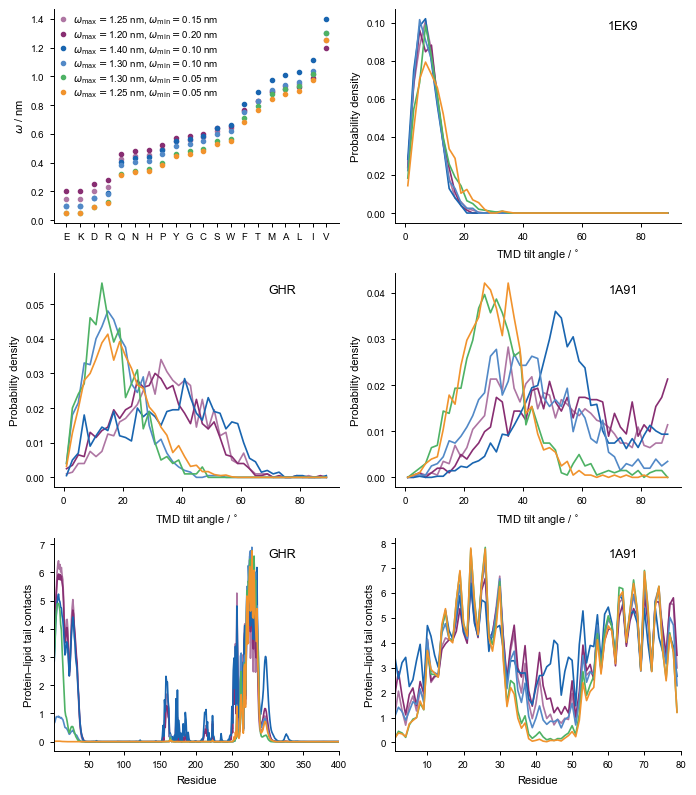

In [86]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

folders = ['125_15', '120_20', '140_10', '130_10', '130_05', '125_05']
proteins = ['1EK9', 'GHR', '1A91']
principal_axis = [2, 0, 0]
colors = ['purple2','purple3',
    'blue1','blue2','green1','orange1']

df = pd.read_csv('data/WLXLL/residues_v2.csv', index_col=0)
aas_list = df.iloc[:20].sort_values('omega').index.values

bins = np.arange(0, 92, 2)
x = (bins[:-1] + bins[1:]) / 2

fig, axes = plt.subplots(3, 2, figsize=(7, 8))
axes = axes.flatten()

for folder, color in zip(folders, colors):
    df_scan = pd.read_csv(f'data/v2_scan/{folder}/residues.csv', index_col=0)
    
    label = '$\omega_\mathrm{max}=$'+', $\omega_\mathrm{min}=$'.join(f'{int(v)/100:.2f} nm' for v in folder.split('_'))

    axes[0].plot(aas_list, df_scan.loc[aas_list, 'omega'],
                 marker='o', ms=3, lw=0, color=rnb_colors[color], label=label)

    for ax, protein, pa in zip(axes[1:], proteins, principal_axis):
        a = np.load(f'data/v2_scan/{folder}/{protein}_0_domain_angles.npy',
                    allow_pickle=True).item()['TMD'][:, pa]
        hist = np.histogram(a, bins=bins, density=True)[0]
        ax.plot(x, hist, color=rnb_colors[color], lw=1.2, label=folder)
        
    for ax, protein in zip(axes[4:], ['GHR', '1A91']):
        cprofile = np.load(
            f'data/v2_scan/{folder}/{protein}_0_protein_lipid_cmap.npy'
        ).sum(axis=1)

        ax.plot(np.arange(1, len(cprofile) + 1), cprofile,
                color=rnb_colors[color], lw=1.2, label=folder)

axes[0].set_ylabel(r'$\omega$ / nm')

for ax, protein in zip(axes[1:4], proteins):
    ax.set_xlabel(r'TMD tilt angle / $^{\circ}$')
    ax.set_ylabel('Probability density')
    ax.text(0.85, 0.95, protein, transform=ax.transAxes,
            ha='right', va='top', fontsize=9)
    
for ax, protein in zip(axes[4:], ['GHR', '1A91']):
    ax.set_xlabel('Residue')
    ax.set_ylabel('Protein–lipid tail contacts')
    ax.text(0.85, 0.95, protein, transform=ax.transAxes,
            ha='right', va='top', fontsize=9)

axes[4].set_xlim(1,400)
axes[5].set_xlim(1,80)

for ax in axes:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

axes[0].legend(frameon=False, fontsize=7, borderpad=0,
               handletextpad=0.5, handlelength=1, labelspacing=0.2)

plt.tight_layout()
plt.savefig('figS8.pdf')
plt.show()